In [1]:
################### Imports ####################
##  Test File
##  Author: Hyun Woo Kim
##  GTid: hkim866
##  Date of Submission: 03/04/2022
#####################################################\
# Universal imports
import datetime as dt
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import re
import time

from sklearn.metrics import r2_score
import pickle

In [2]:
################ Function getAPIData  ####################
##  sub function to import data from skyspark web data grabber
##  inputs: A json object with method, endpoint, date range, interval, and fold method
##  outputs: A Pandas Series object
########################################################
def getAPIData(inputs, test = None):
    # data url and retrival request
    url = "https://fm-energywatch.ad.gatech.edu/skysparkBackend/"
    r = requests.post(url,json=inputs)

    # quick and easy module for inidividual data testing
    if test is not None:
        pd.set_option('display.max_rows', 10)
        pd.set_option('display.max_columns', None)
        print('API test')
        print(r.text)

    # metadata variable extractor
    meta = r.text.split('\n')[1]
    kind = re.search('kind:\"(.+?)\"',meta).group(1)

    # Removing unit from end of data
    try:
        unitLength = -len(re.search('unit:\"(.+?)\"',meta).group(1))
    except AttributeError:
        unitLength = None

    # extract values -> split into dates and values
    v = r.text.split('\n')[2:-2]
    output = pd.Series([value.split(',')[1][:unitLength] for value in v], name = 'Values')
    output.index = pd.Series([value.split(',')[0] for value in v], name = 'Date/Time')

    # adjust datetime, remove localization info to standardize data
    output.index = pd.to_datetime(output.index, format='%Y-%m-%dT%H:%M:%S%z New_York', utc = True)
    output.index = pd.to_datetime(output.index, format='%Y-%m-%d %H:%M:%S+00:00').tz_convert(tz = 'EST')
    output.index = output.index.tz_localize(None)
  
    # getting values, removing units, and changing to float if number
    if kind == 'Number': # changing string values to float if metadata label = number
        output = pd.to_numeric(output, errors = 'coerce') # set to NaN if value is missing or wrong
    
    return output

In [3]:
################ multiDataRetrieve ###################
def multiDataRetrieve(endpoints, mthd, date):
    df = pd.DataFrame()

    for key in endpoints:
        res = getAPIData({'method': mthd, 'endpoint': endpoints[key],\
            'date': date})
        df[key] = res

    df = daylightSavingAdj(df) # outputting array already adjusted for daylight savings
    return df

In [4]:
################ Function daylightSavingAdj #############
##  Function daylightSavingAdj(inputs):
##  sub function to adjust daylight savings time periods
##  inputs: A time series dataFrame
##  outputs: adjusted dataframe
########################################################
def daylightSavingAdj(input_df):
    # drops first line if it includes previous date (due to daylight savings)
    if input_df.index[0].hour > 1:
            input_df =  input_df.drop(input_df.index[[0]])

    #copies last data point if it is missing last data point (due to daylight savings)
    if input_df.index[-1].hour == 22 :
        new_date = dt.datetime(input_df.index[-1].year,input_df.index[-1].month,input_df.index[-1].day,23,0,0)
        append_row = pd.DataFrame(input_df[-1:].values, index=[new_date], columns=input_df.columns)
        input_df = pd.concat([input_df, append_row], axis = 0)
        
    return input_df

In [5]:
################ Function dataInterpolate ###################
def dataInterpolate(input_df):
    # Simple operationData interpolation algorithm to get rid of unnecessary data points / interpolate for removed data points
    input_df = input_df.resample('H').mean()
    input_df = input_df.interpolate(method='linear')
    return input_df

In [6]:
################ Function removeSpike ###################
##  Function removeSpike(inputs, name, spike, avgSpike):
##  sub function to remove spikes in Data
##  inputs: A time series dataFrame
##  outputs: adjusted dataframe
#########################################################
def removeSpike(df, spike, avgSpike):

    dropRows = []
    intVal = df.iloc[0]
    
    for x in range(1,len(df.index)-1):
        val = df.iloc[x]
        if abs(val - intVal) > spike:
            dropRows.append(x)
        elif x > 24:
            avgVal = np.mean(df.iloc[x-24:x])
            if abs(avgVal - intVal) > avgSpike:
                dropRows.append(x)

    df.drop(df.index[dropRows], axis=0, inplace = True)

    df = df.resample('H').mean()
    df = df.interpolate(method='linear')

    return df

In [7]:
#'DA T':         '@p:gaTech:r:250aa126-5765f56d',
#'OA T':         '@p:gaTech:r:250aa127-4b5ead93',
#'MA T':         '@p:gaTech:r:250aa127-29738504',
#'OA F':         '@p:gaTech:r:250aa127-54912f24',
#'RA T':         '@p:gaTech:r:250aa127-27153a48',
#'EA T':         '@p:gaTech:r:250aa126-21b63b76',
#'EA F':         '@p:gaTech:r:250aa126-0fd4b334',
#'DA T Enthalpy':'@p:gaTech:r:250aa128-19d7cf77',
#'OA T Enthalpy':'@p:gaTech:r:25165a78-cd18429f',
#'MA T Enthalpy':'@p:gaTech:r:25165a78-3fd10ee0', # Is Heat Recover Wheel Discharge Air, may not be MAT
#'RA T Enthalpy':'@p:gaTech:r:25165a78-6801155e',
#'EA T Enthalpy':'@p:gaTech:r:250aa128-331109a9',
#'RAD CHW O':    "@p:gaTech:r:250bb9ae-8f4ea2e2", #B210 Plant RADIANT CHWR-O
#'RAD CHW T':    "@p:gaTech:r:250bb9ae-afd2d0ee", #B210 Plant RADCHWR-T
#'RAD HW O':     "@p:gaTech:r:250bb9ae-24ab51fe", #B210 Plant RADIANT HWR-O
#'RAD HW T':     "@p:gaTech:r:250bb9ae-8e71164c", #B210 Plant RADHWR-T

In [8]:
################ Function getData ######################
##  sub function to retrieve data
##  inputs: start and end date
##  outputs: dataframe
########################################################
def getData(startDate, endDate): # querying data from skySpark API
    # Default settings for data retrieval
    mthd = 'getDataAll'
    date = startDate + ".." + endDate
    #rolp = 'None'
    #intv = '15min'

    endpoints = {
        # Setting up API access point directory
        'WBT':          '@p:fm_meters:r:290476e3-c2d21c72',
        'RH':           '@p:fm_meters:r:290476d9-485c7d15',
        'DBT':          '@p:fm_meters:r:290a056d-6f126796',
        'solarIrrad':   '@p:fm_meters:r:290476b1-4abf5ef4',
        'Kendeda CHW':  '@p:gaTech:r:253c9dfb-55fdfd96',
        'Kendeda CHW Tot':  '@p:gaTech:r:253c9db0-d03d5efd',
        'Kendeda CCHW Tot':  '@p:gaTech:r:253c9db0-d03d5efd',
        'Kendeda CCHW Ton':  '@p:gaTech:r:253c9dad-c01f1b28',
        'Kendeda CCHW RT':  '@p:gaTech:r:253c9da7-9253b997',
        'Kendeda CCHW ST':  '@p:gaTech:r:253c9daa-31a99a87',
        'Kendeda CCHW F':  '@p:gaTech:r:253c9da2-896a91f7',

    }

    data = multiDataRetrieve(endpoints, mthd, date)
    data = dataInterpolate(data)

    return data

In [9]:
# Pickle Save object
def save_obj(obj, filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)


In [10]:
################ Retrieving Data ################
dataStart = '2022-01-01' #start Date is from 06-08 as that is when occupancy data is available
dataEnd = '2023-06-01'

# retrieving data from API in one go
#APIdata = getData(dataStart, dataEnd)

#kendeda = read_obj('kendeda')
#weather = read_obj('weather')
#energy = read_obj('energy')

In [45]:
#save_obj(APIdata,'APIdata2')
APIdata = read_obj('APIdata2')
weather = read_obj('weather')

In [46]:
index = APIdata.index
#operation = kendeda.operationData
#response = kendeda.responseData
#index = weather.index

In [57]:
def highlightEqual(series, val, colorSTR):
    # Create a mask to identify where the Series values equal 4
    mask = (series == val)

    # Find the start and end indices of each continuous section where the value equals 4
    section_start = mask & ~mask.shift(fill_value=False)
    section_end = mask & ~mask.shift(-1, fill_value=False)

    for start, end in zip(section_start[section_start].index, section_end[section_end].index):
        plt.axvspan(start, end, color=colorSTR, alpha=0.5)

In [58]:
def highlightComaprison(series, val, colorSTR):
    # Create a mask to identify where the Series values equal 4
    mask = (abs(series) < val)

    # Find the start and end indices of each continuous section where the value equals 4
    section_start = mask & ~mask.shift(fill_value=False)
    section_end = mask & ~mask.shift(-1, fill_value=False)

    for start, end in zip(section_start[section_start].index, section_end[section_end].index):
        plt.axvspan(start, end, color=colorSTR, alpha=0.5)

In [113]:
def highlightComaprison2(series, val, colorSTR):
    # Create a mask to identify where the Series values equal 4
    mask = ((series) > val)


    # Find the start and end indices of each continuous section where the value equals 4
    section_start = mask & ~mask.shift(fill_value=False)
    section_end = mask & ~mask.shift(-1, fill_value=False)

    for start, end in zip(section_start[section_start].index, section_end[section_end].index):
        plt.axvspan(start, end, color=colorSTR, alpha=0.5)

In [61]:
calc_flow = (APIdata['Kendeda CCHW RT'] - APIdata['Kendeda CCHW ST']) * APIdata['Kendeda CCHW F'] /22
calc_flow[abs(calc_flow) > 200] = None

In [62]:
diff_chw = APIdata['Kendeda CCHW Tot'].diff()
diff_chw[abs(diff_chw) > 200] = None

ton_chw = APIdata['Kendeda CCHW Ton']
ton_chw[abs(ton_chw) > 200] = None



f_chw = APIdata['Kendeda CCHW F'].copy()
f_chw[abs(f_chw) > 5000] = None

<Figure size 432x288 with 0 Axes>

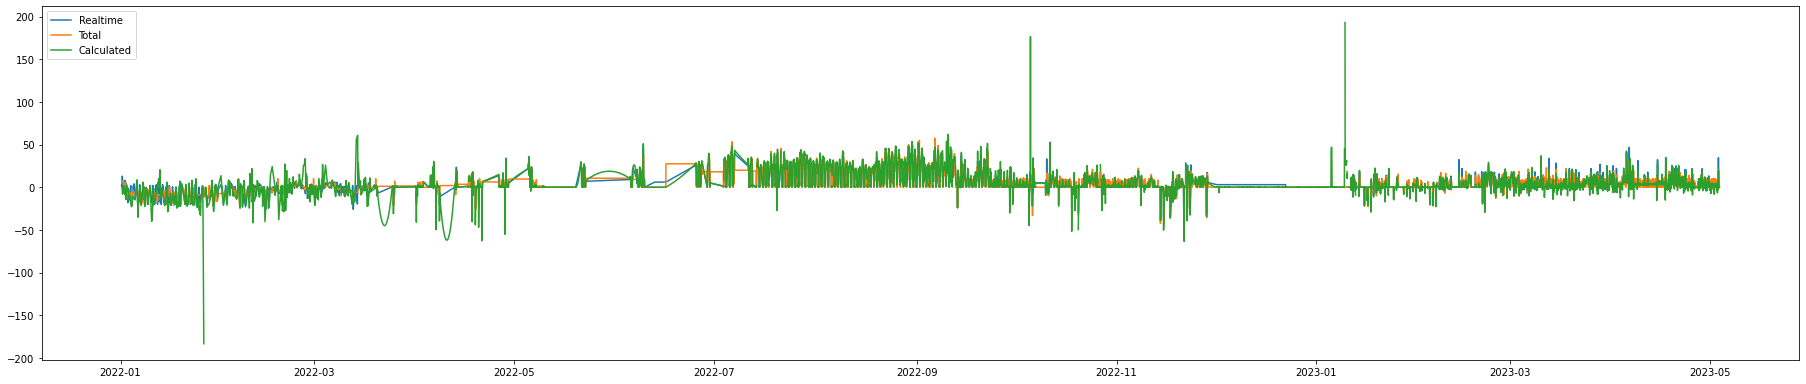

<Figure size 432x288 with 0 Axes>

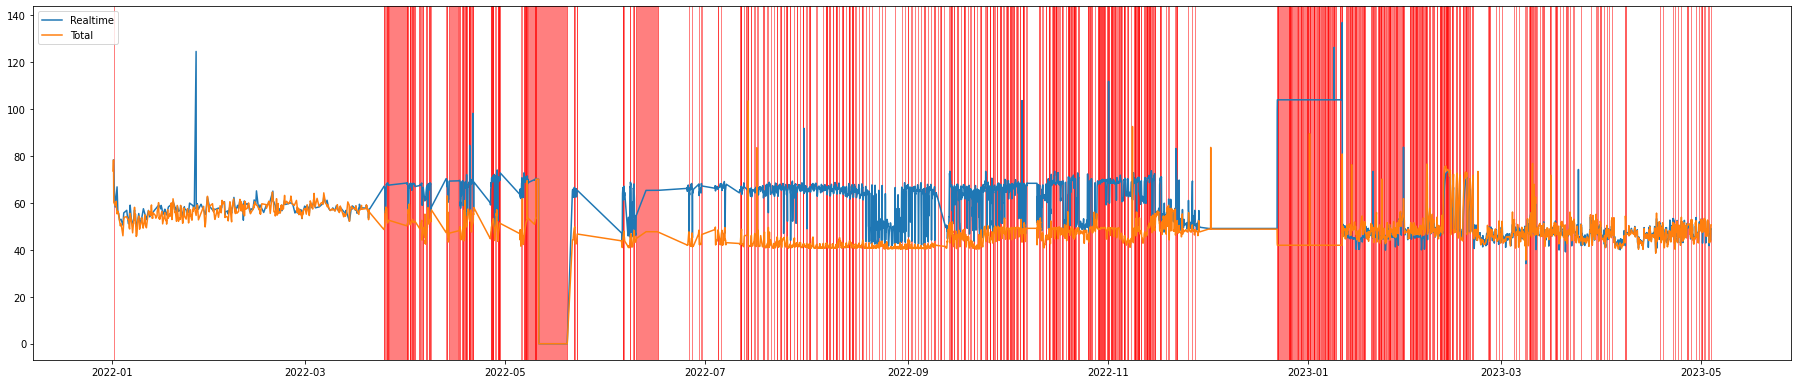

<Figure size 432x288 with 0 Axes>

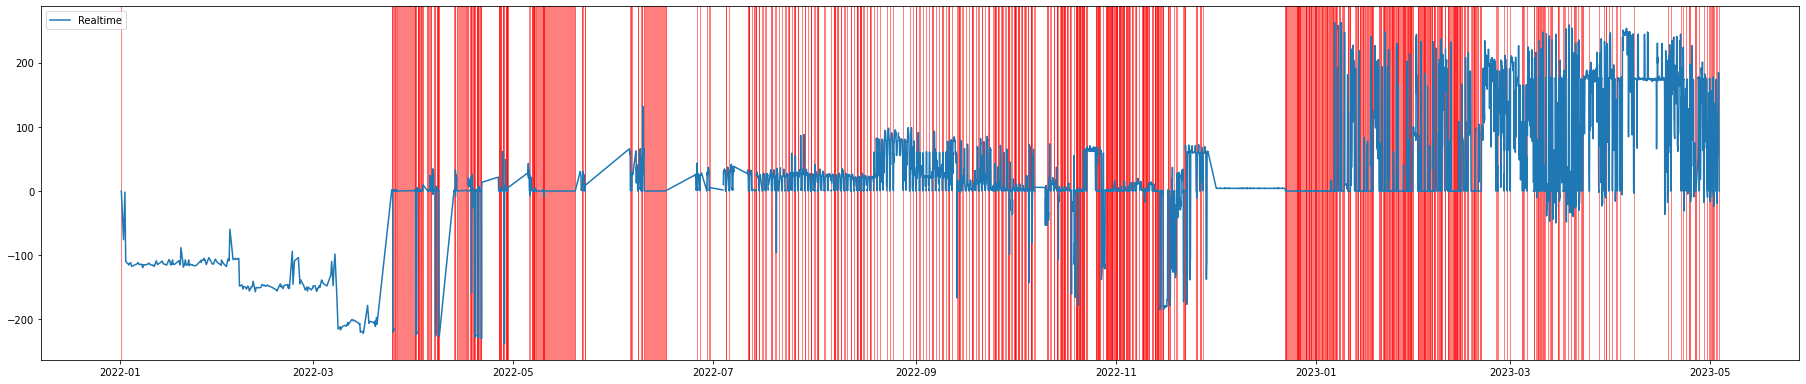

In [69]:
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, ton_chw, label = 'Realtime')
plt.plot(index, diff_chw, label = 'Total')
plt.plot(index,calc_flow, label = 'Calculated')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, APIdata['Kendeda CCHW RT'], label = 'Realtime')
plt.plot(index, APIdata['Kendeda CCHW ST'], label = 'Total')
highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, f_chw, label = 'Realtime')
highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

c:\Users\Hyun Woo Kim\AppData\Local\Programs\Python\Python39\lib\site-packages\pandas\core\arraylike.py:364: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\Hyun Woo Kim\AppData\Local\Programs\Python\Python39\lib\site-packages\pandas\core\arraylike.py:364: RuntimeWarning: invalid value encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


<Figure size 432x288 with 0 Axes>

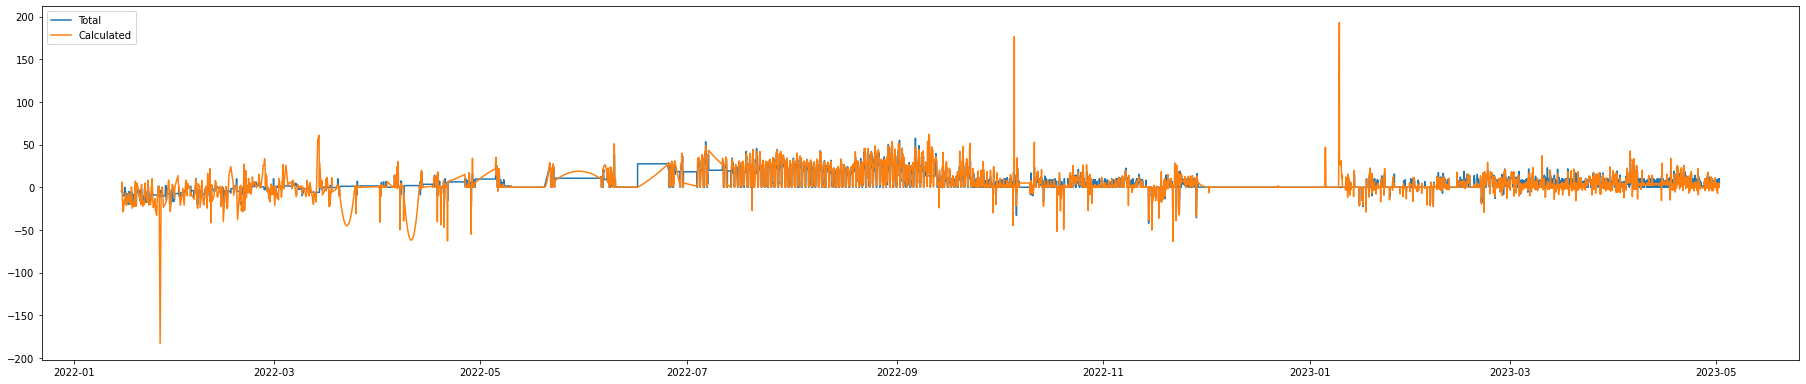

<Figure size 432x288 with 0 Axes>

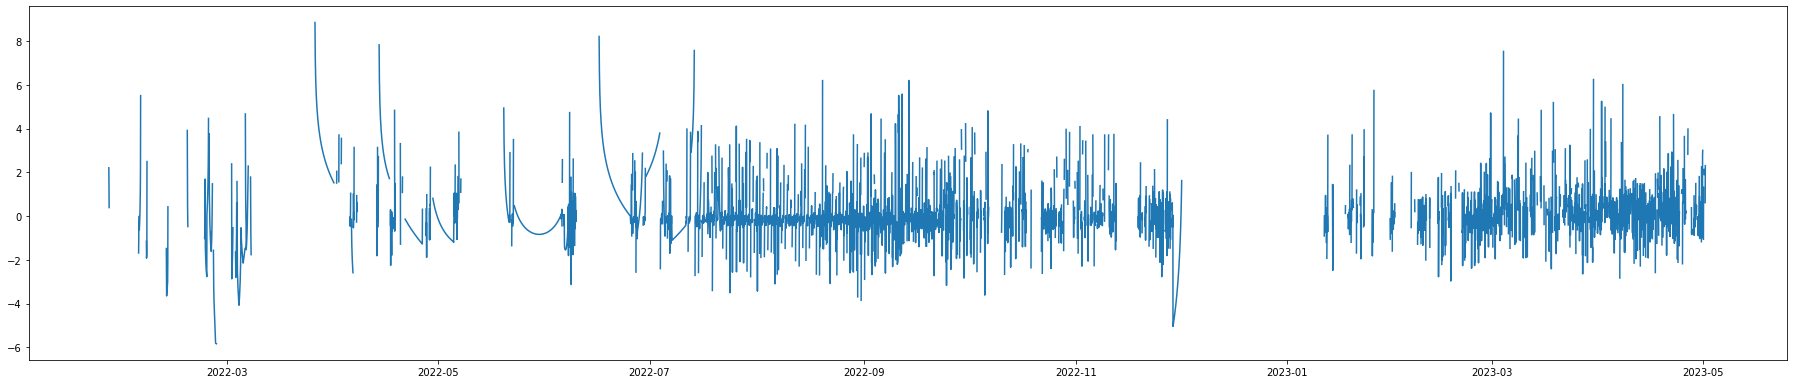

<Figure size 432x288 with 0 Axes>

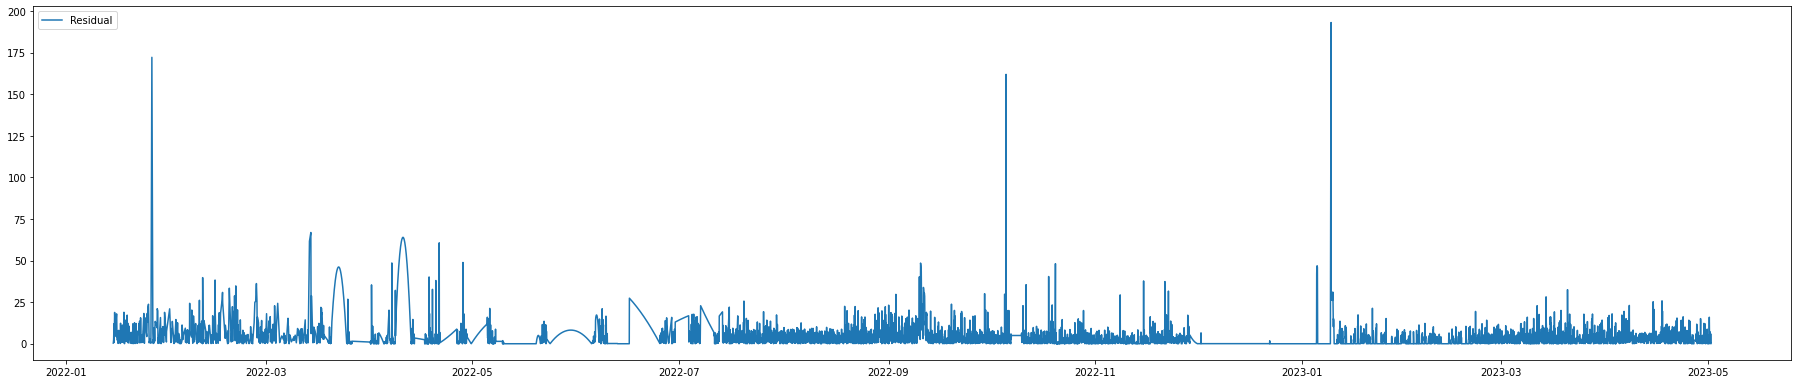

<Figure size 432x288 with 0 Axes>

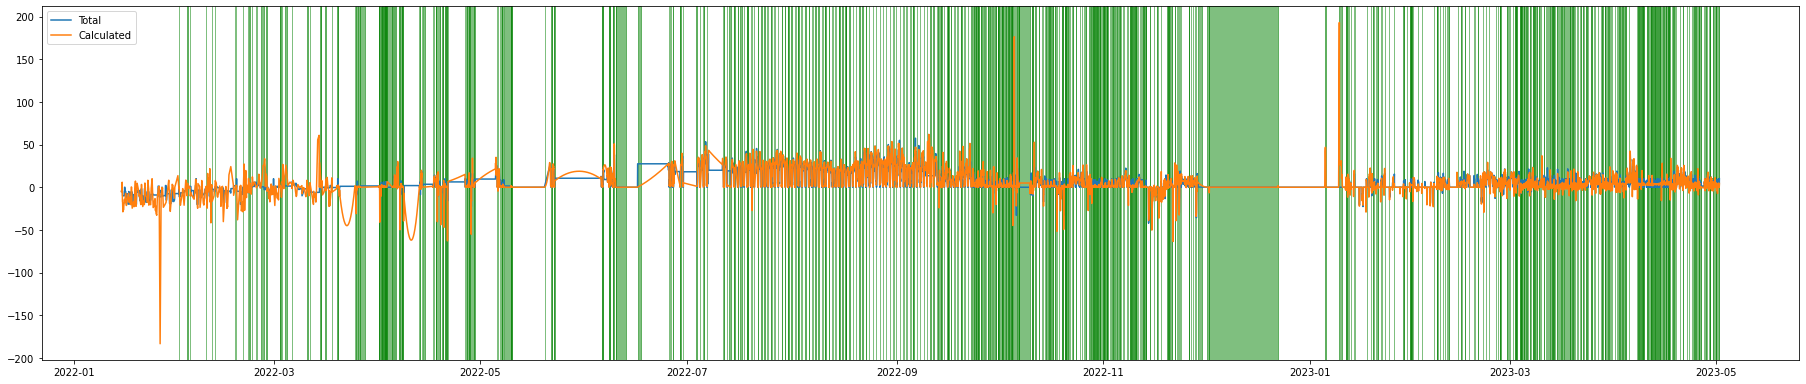

<Figure size 432x288 with 0 Axes>

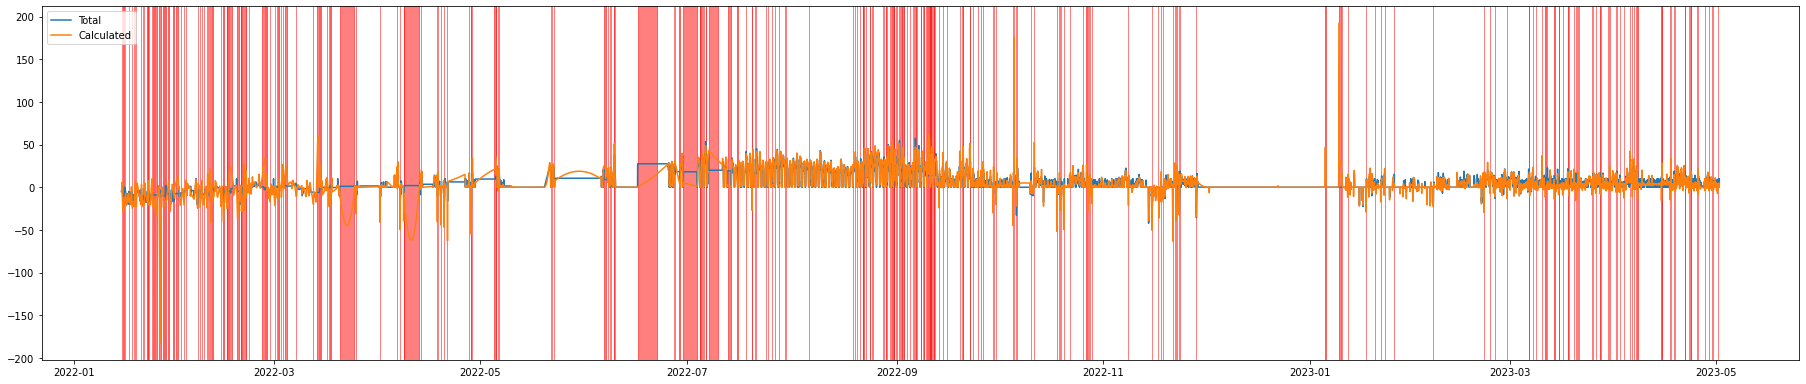

In [114]:
sd = "2022-01-15"
ed = "2023-05-01"

index = ton_chw.loc[sd:ed].index

diff_chw = diff_chw.interpolate(method='linear')
calc_flow = calc_flow.interpolate(method='linear')

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, diff_chw.loc[sd:ed], label = 'Total')
plt.plot(index,calc_flow.loc[sd:ed], label = 'Calculated')
plt.legend(loc="upper left")

filter1 =  abs(np.log2(diff_chw.loc[sd:ed]) - np.log2(calc_flow.loc[sd:ed]))
filter2 = np.log2(abs(diff_chw.loc[sd:ed] - calc_flow.loc[sd:ed]))

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, np.log2(diff_chw.loc[sd:ed]) - np.log2(calc_flow.loc[sd:ed]), label = 'Residual 2')

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, abs(diff_chw.loc[sd:ed] - calc_flow.loc[sd:ed]), label = 'Residual')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, diff_chw.loc[sd:ed], label = 'Total')
plt.plot(index,calc_flow.loc[sd:ed], label = 'Calculated')
highlightComaprison2(filter1, 3.5, 'green')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, diff_chw.loc[sd:ed], label = 'Total')
plt.plot(index,calc_flow.loc[sd:ed], label = 'Calculated')
highlightComaprison2(filter2, 3.5, 'red')
plt.legend(loc="upper left")

c:\Users\Hyun Woo Kim\AppData\Local\Programs\Python\Python39\lib\site-packages\pandas\core\arraylike.py:364: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


<AxesSubplot:>

<Figure size 432x288 with 0 Axes>

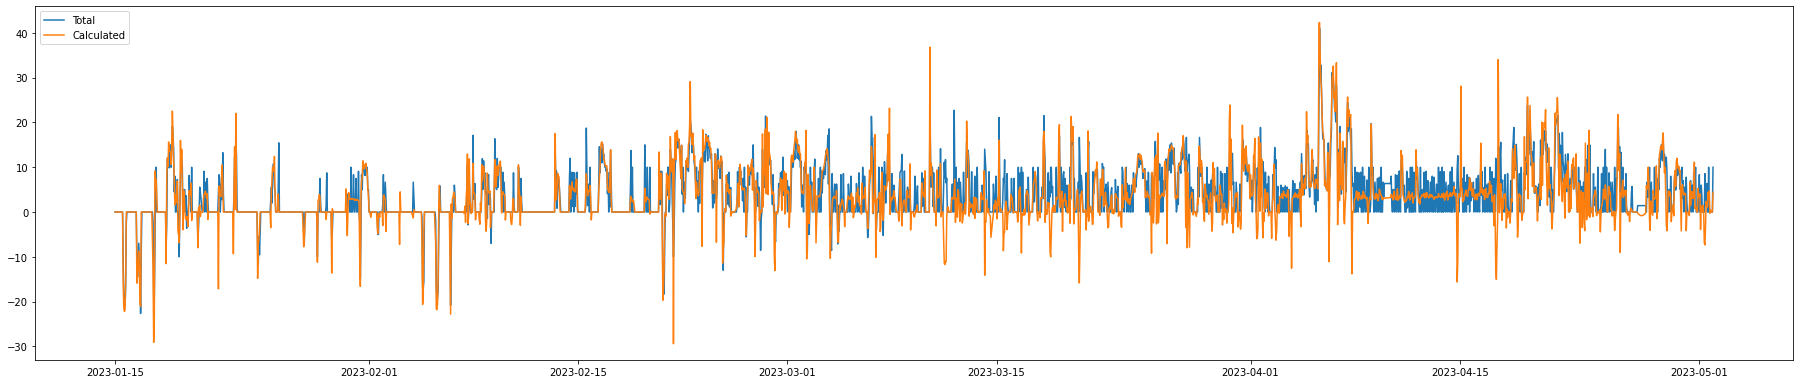

<Figure size 432x288 with 0 Axes>

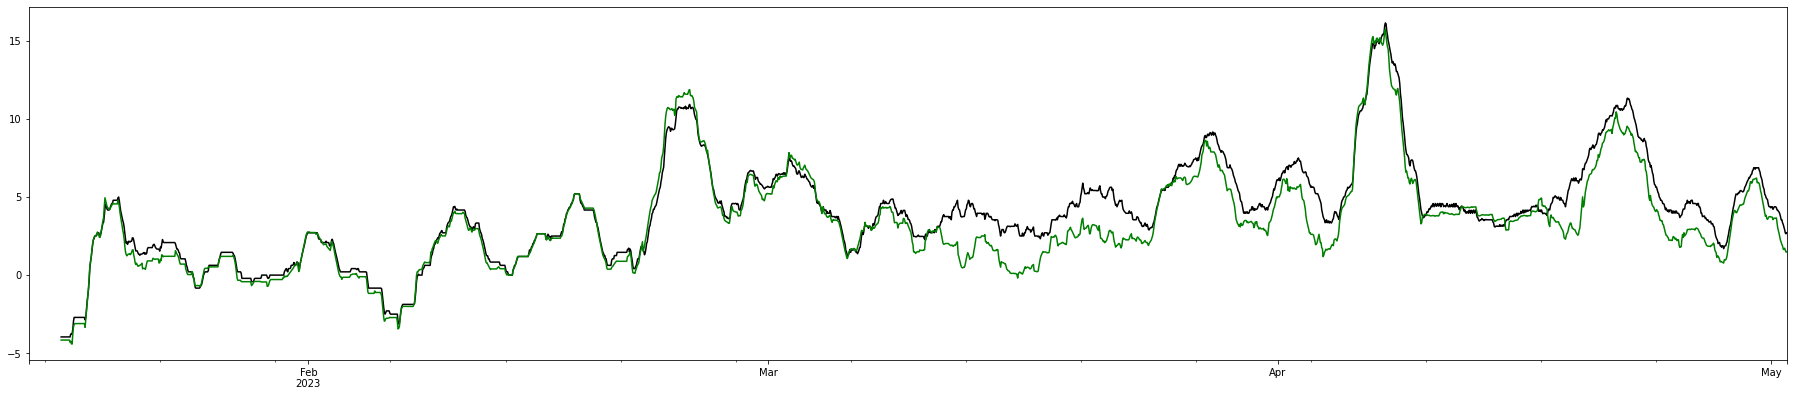

<Figure size 432x288 with 0 Axes>

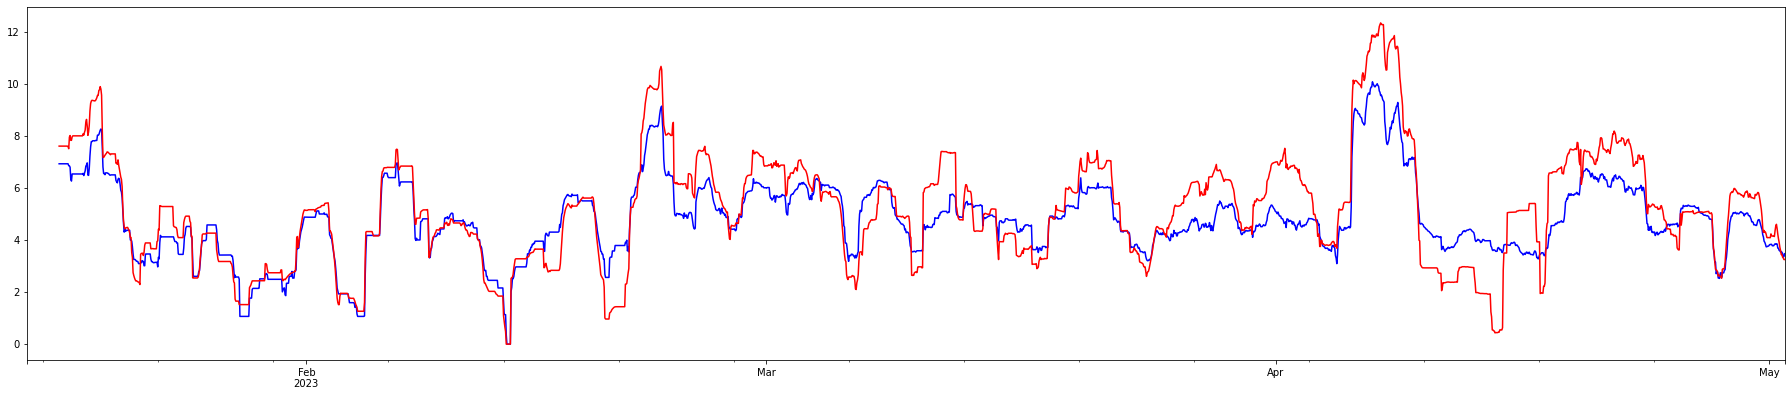

<Figure size 432x288 with 0 Axes>

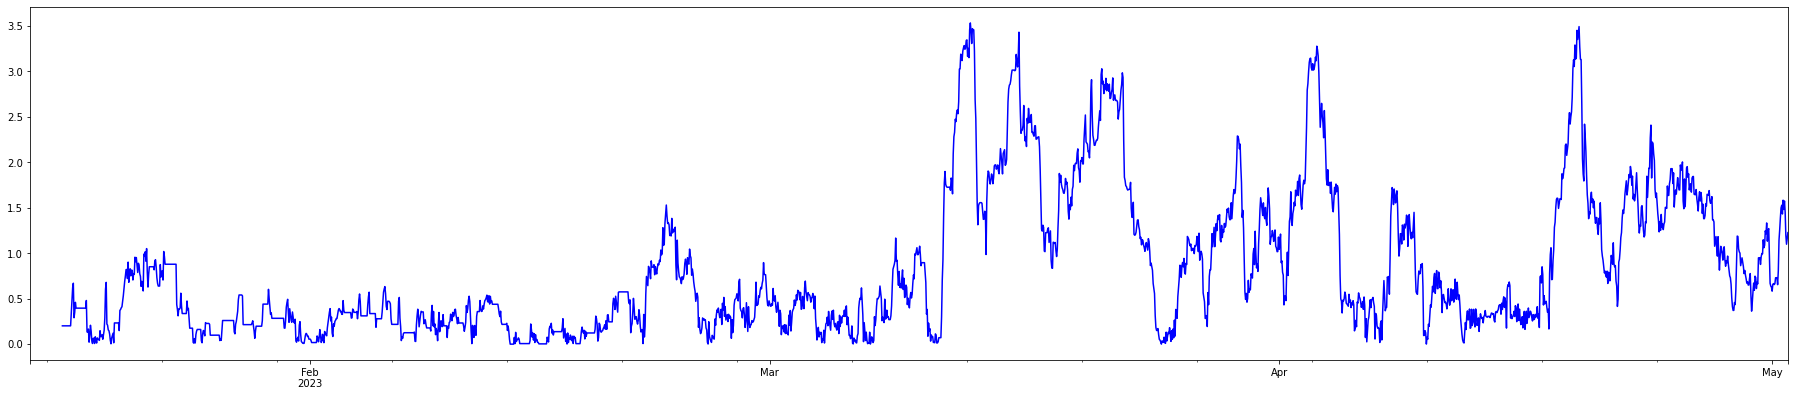

<Figure size 432x288 with 0 Axes>

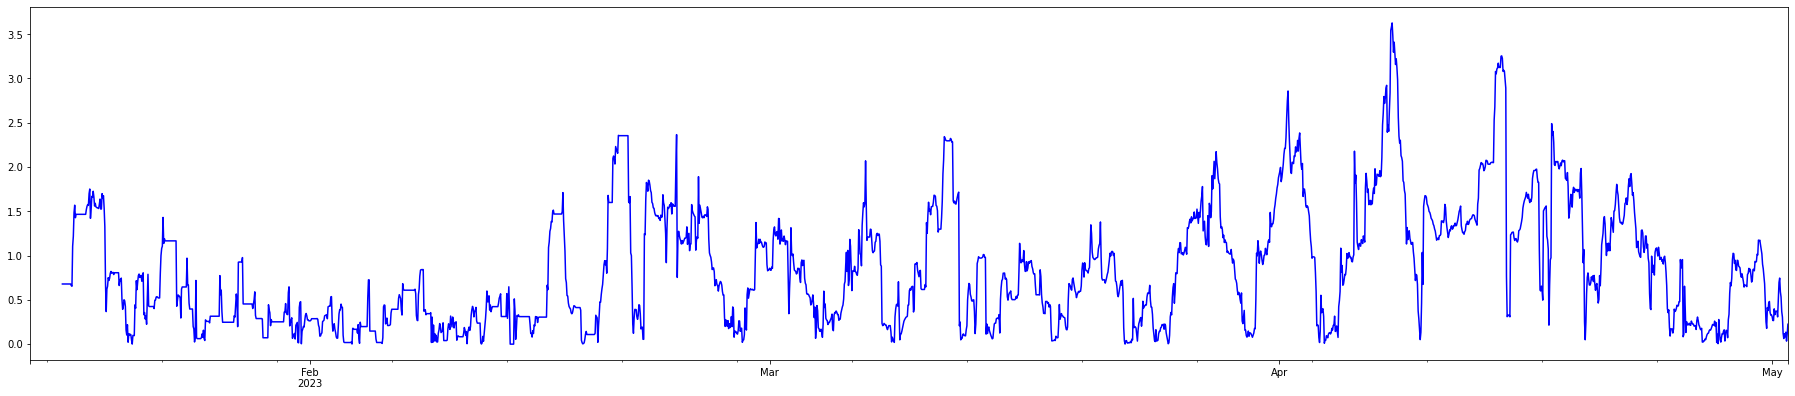

In [135]:
sd = "2023-01-15"
ed = "2023-05-01"
index =  diff_chw.loc[sd:ed].index
filter2 = np.log2(abs(diff_chw.loc[sd:ed] - calc_flow.loc[sd:ed]))


plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, diff_chw.loc[sd:ed], label = 'Total')
plt.plot(index, calc_flow.loc[sd:ed], label = 'Calculated')
#highlightComaprison2(filter2, 3, 'red')
plt.legend(loc="upper left")

win_size = 24*2

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
ts1 = diff_chw.loc[sd:ed]
ts2 = calc_flow.loc[sd:ed]
# calculate a 60 day rolling mean and plot
ts1.rolling(window=win_size).mean().plot(style='k')
ts2.rolling(window=win_size).mean().plot(style='g')

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
ts1.rolling(window=win_size).std().plot(style='b')
ts2.rolling(window=win_size).std().plot(style='r')

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
abs(ts1.rolling(window=win_size).mean() - ts2.rolling(window=win_size).mean()).plot(style='b')

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
abs(ts1.rolling(window=win_size).std() - ts2.rolling(window=win_size).std()).plot(style='b')

<Figure size 432x288 with 0 Axes>

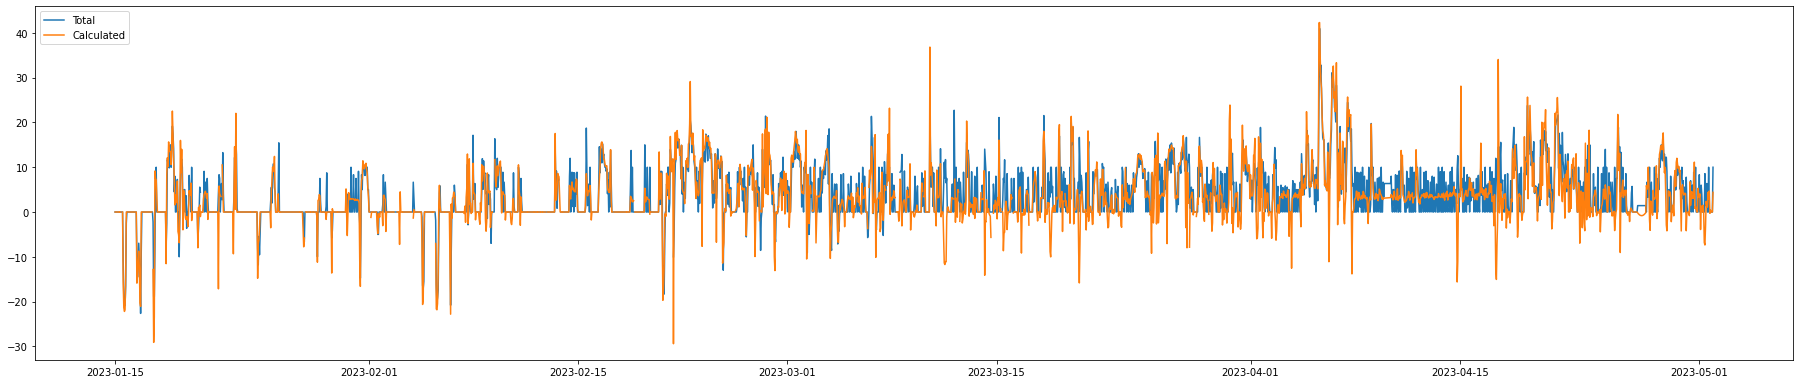

<Figure size 432x288 with 0 Axes>

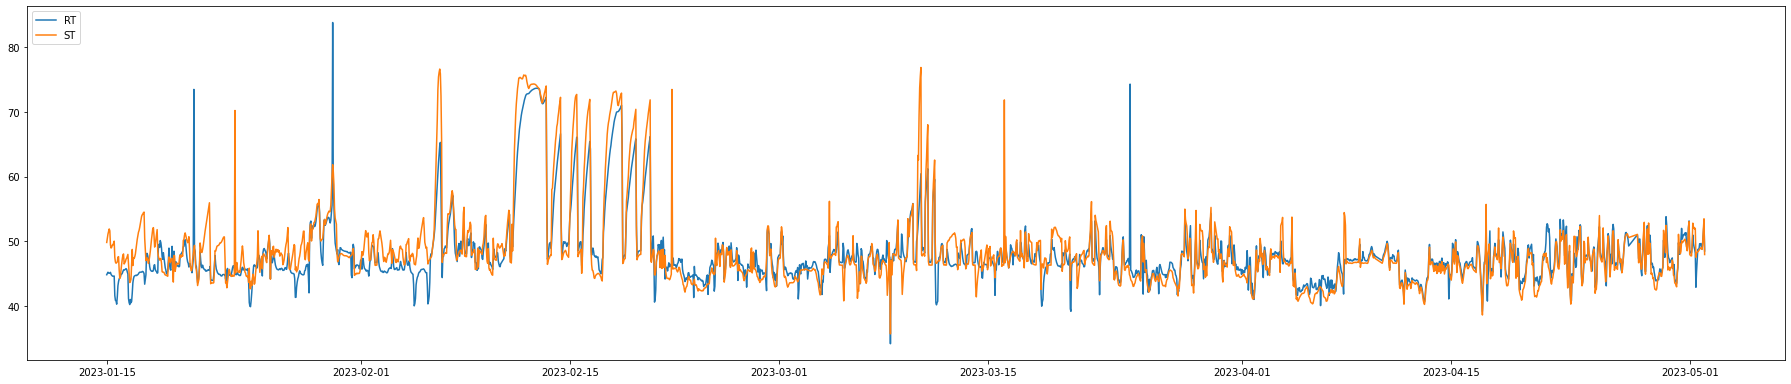

<Figure size 432x288 with 0 Axes>

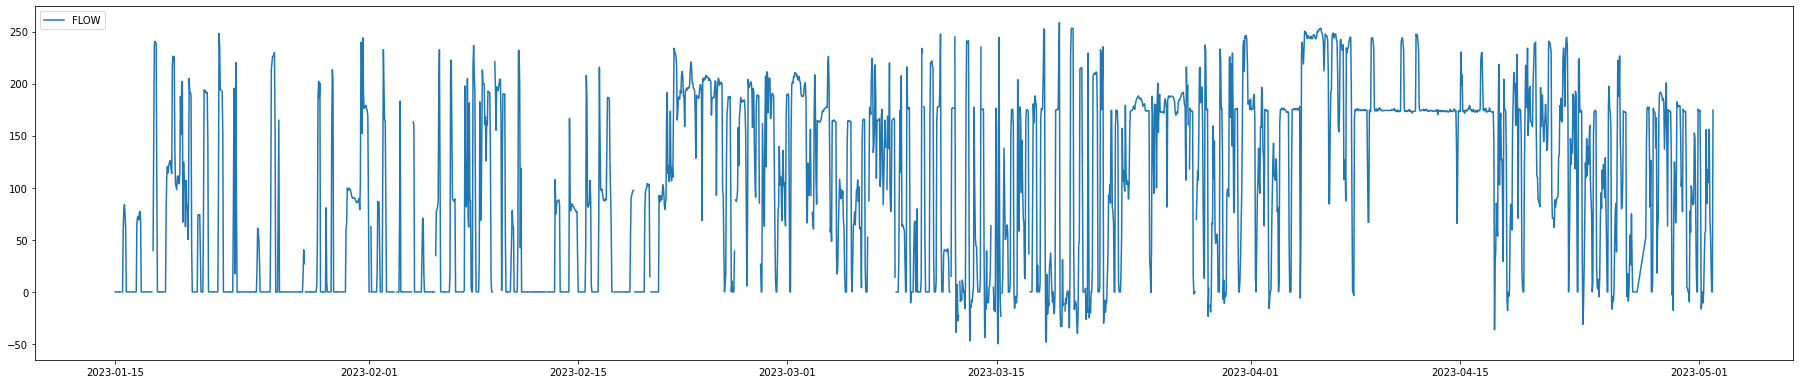

In [77]:
index = ton_chw.loc[sd:ed].index

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(index, ton_chw.loc[sd:ed], label = 'Realtime')
plt.plot(index, diff_chw.loc[sd:ed], label = 'Total')
plt.plot(index,calc_flow.loc[sd:ed], label = 'Calculated')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.plot(index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
#highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, f_chw.loc[sd:ed], label = 'FLOW')
#highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

<Figure size 432x288 with 0 Axes>

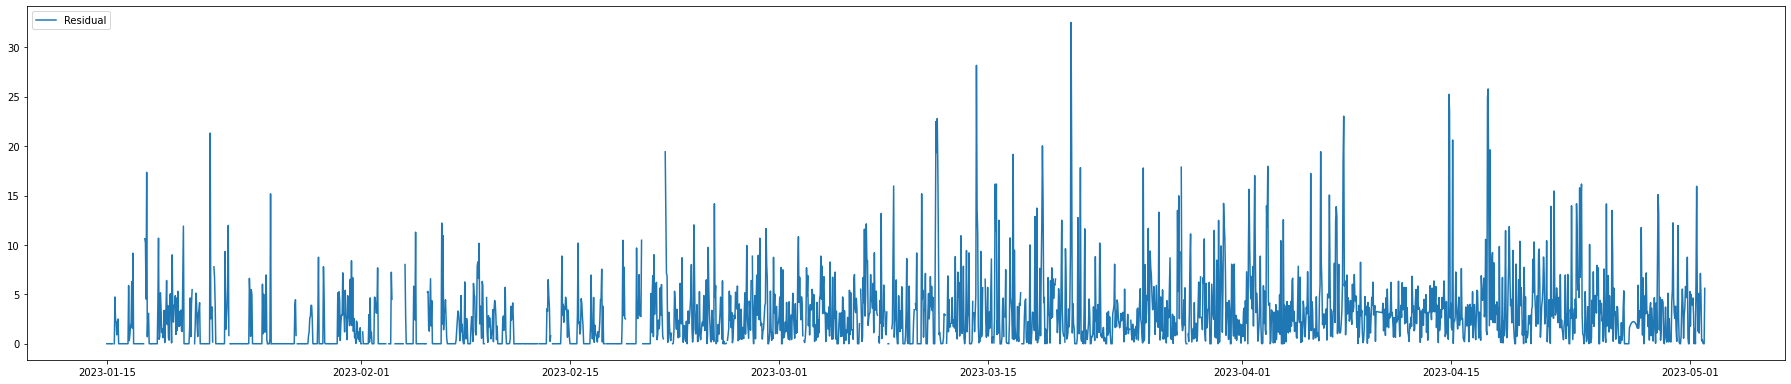

<Figure size 432x288 with 0 Axes>

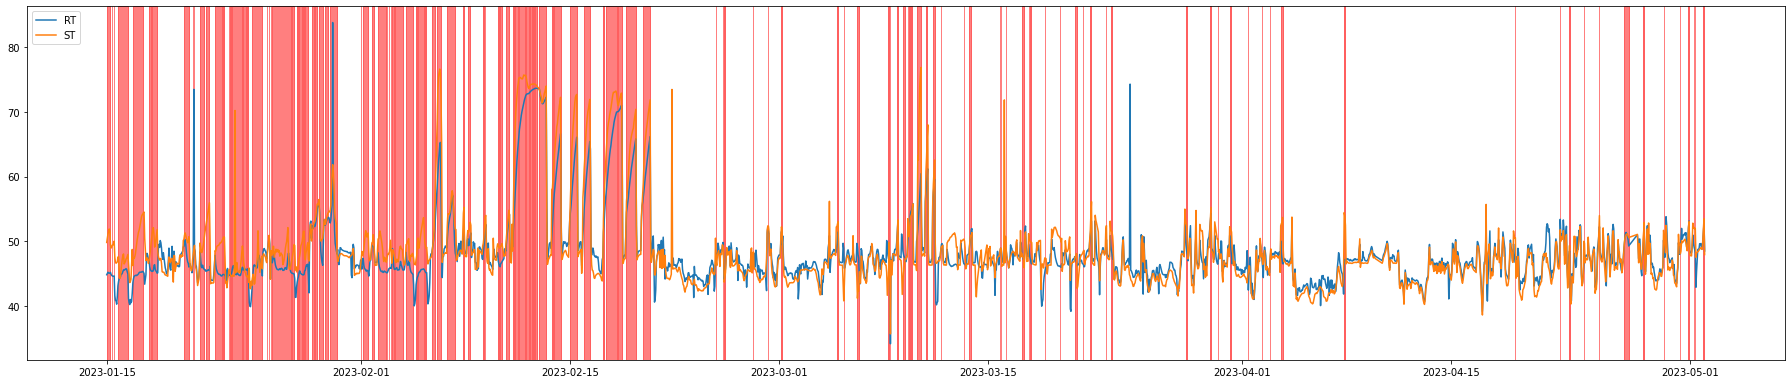

<Figure size 432x288 with 0 Axes>

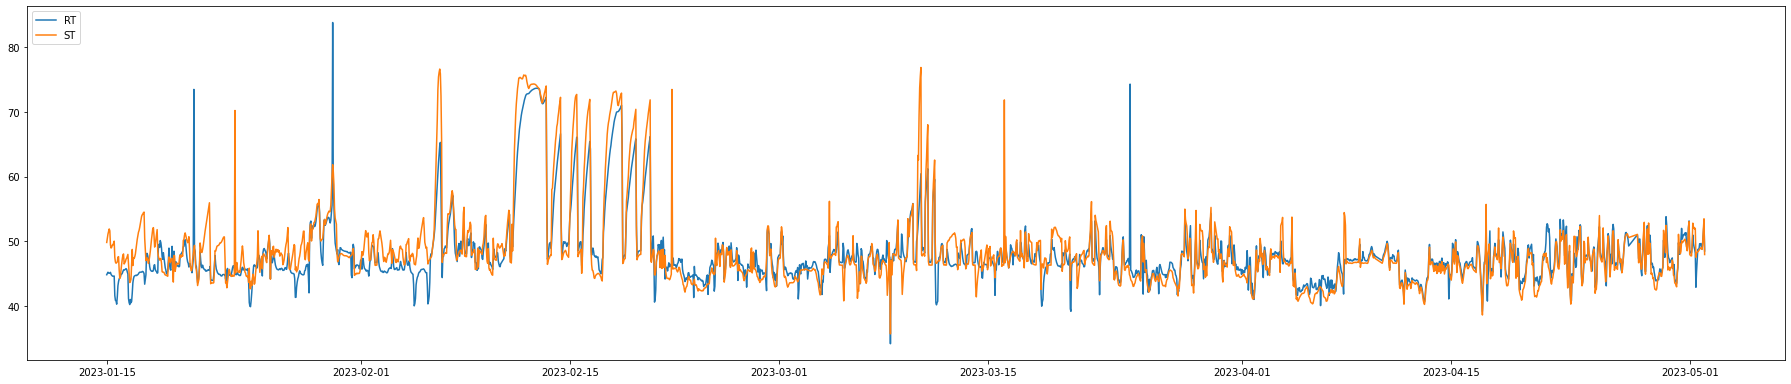

<Figure size 432x288 with 0 Axes>

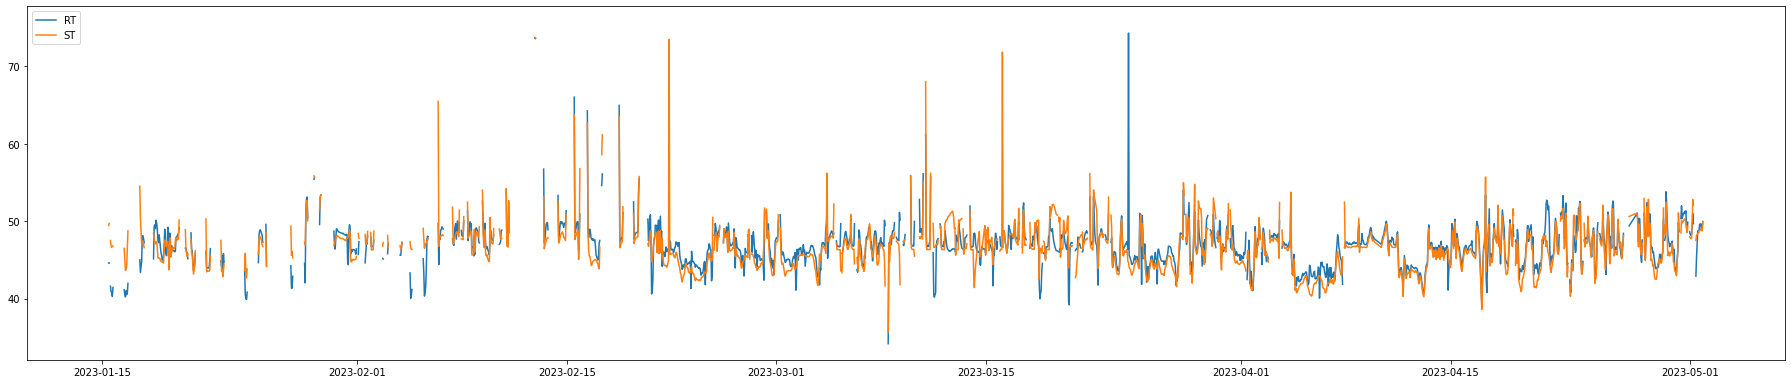

<Figure size 432x288 with 0 Axes>

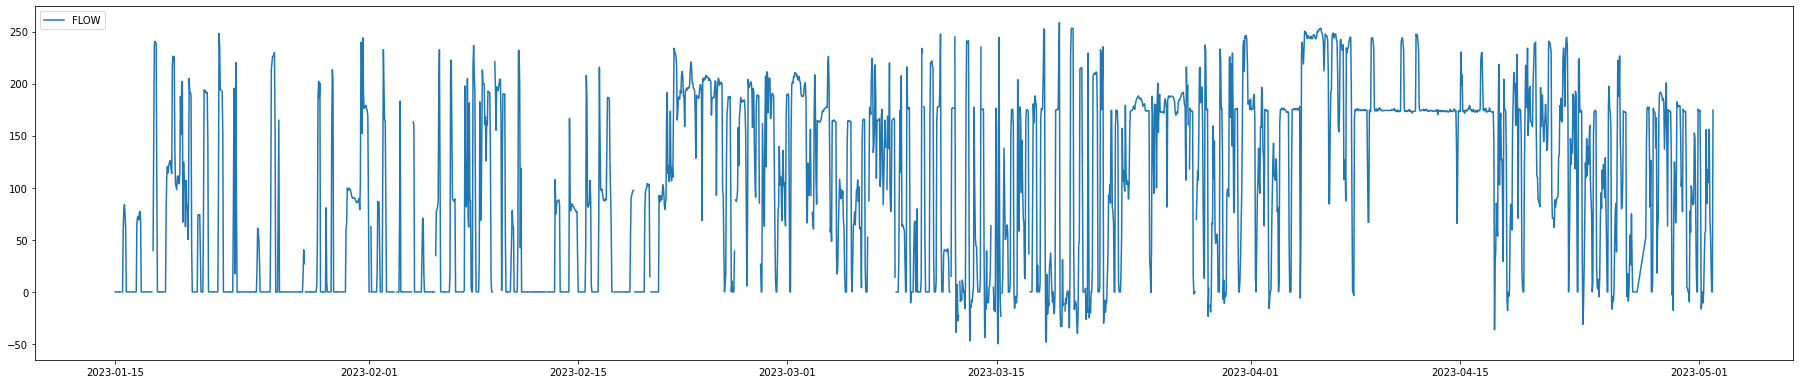

In [86]:
sd = "2023-01-15"
ed = "2023-05-01"

index = ton_chw.loc[sd:ed].index

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, abs(diff_chw.loc[sd:ed] - calc_flow.loc[sd:ed]), label = 'Residual')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.plot(index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
highlightComaprison(f_chw.loc[sd:ed], 0.1, 'red')
plt.legend(loc="upper left")

rt =  APIdata['Kendeda CCHW RT'].copy()
st = APIdata['Kendeda CCHW ST'].copy()

rt[abs(f_chw) < 0.1] = None
st[abs(f_chw) < 0.1] = None

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.plot(index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, rt.loc[sd:ed], label = 'RT')
plt.plot(index, st.loc[sd:ed], label = 'ST')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, f_chw.loc[sd:ed], label = 'FLOW')
#highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

In [ ]:
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, ton_chw, label = 'Realtime')
plt.plot(index, diff_chw, label = 'Total')
plt.plot(index,calc_flow, label = 'Calculated')
highlightComaprison(f_chw, 5, 'green')
highlightComaprison(f_chw, 1, 'red')
plt.legend(loc="upper left")

Text(0.5, 1.0, 'lighting')

<Figure size 432x288 with 0 Axes>

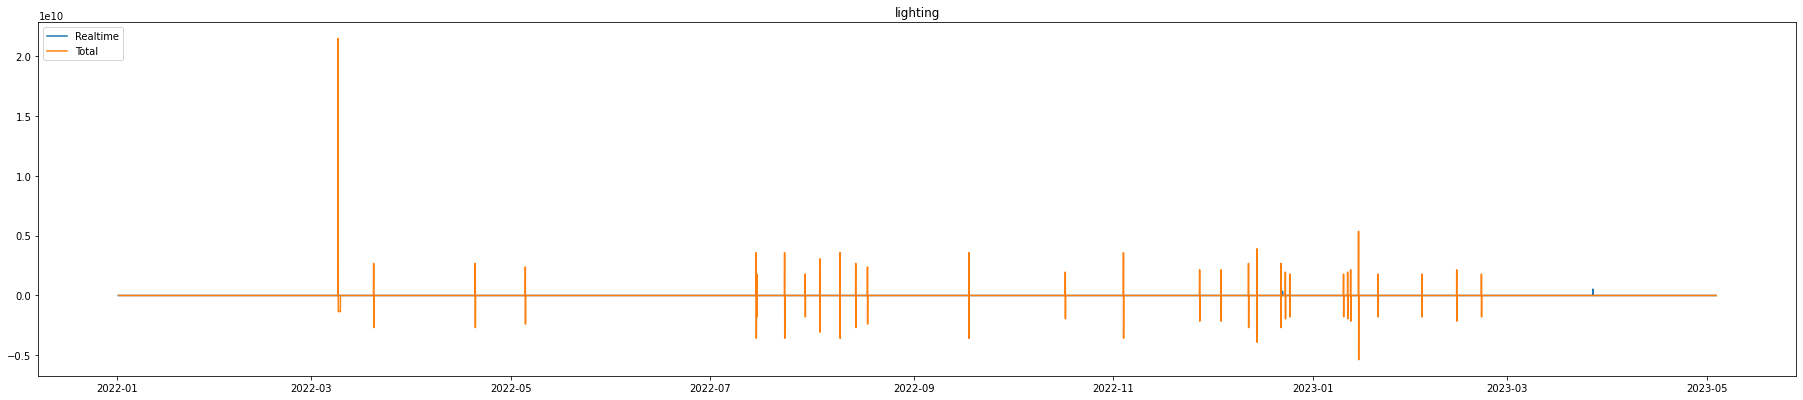

In [14]:
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, APIdata['Kendeda CCHW Ton'], label = 'Realtime')
plt.plot(index, APIdata['Kendeda CCHW Tot'].diff(), label = 'Total')
plt.legend(loc="upper left")
plt.title('lighting')

In [15]:
diff_chw = APIdata['Kendeda CCHW Tot'].diff()
diff_chw[abs(diff_chw) > 1000] = None

ton_chw = APIdata['Kendeda CCHW Ton']
ton_chw[abs(ton_chw) > 1000] = None



f_chw = APIdata['Kendeda CCHW F'].copy()
f_chw[abs(f_chw) > 5000] = None

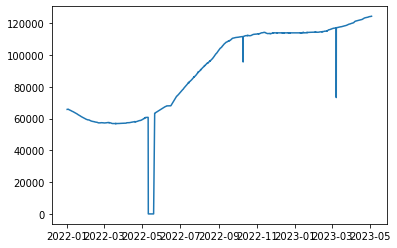

In [16]:
tot_chw = APIdata['Kendeda CCHW Tot']
tot_chw[abs(tot_chw) > 500000] = None
plt.plot(index,tot_chw, label = 'Total')

Text(0.5, 1.0, 'lighting')

<Figure size 432x288 with 0 Axes>

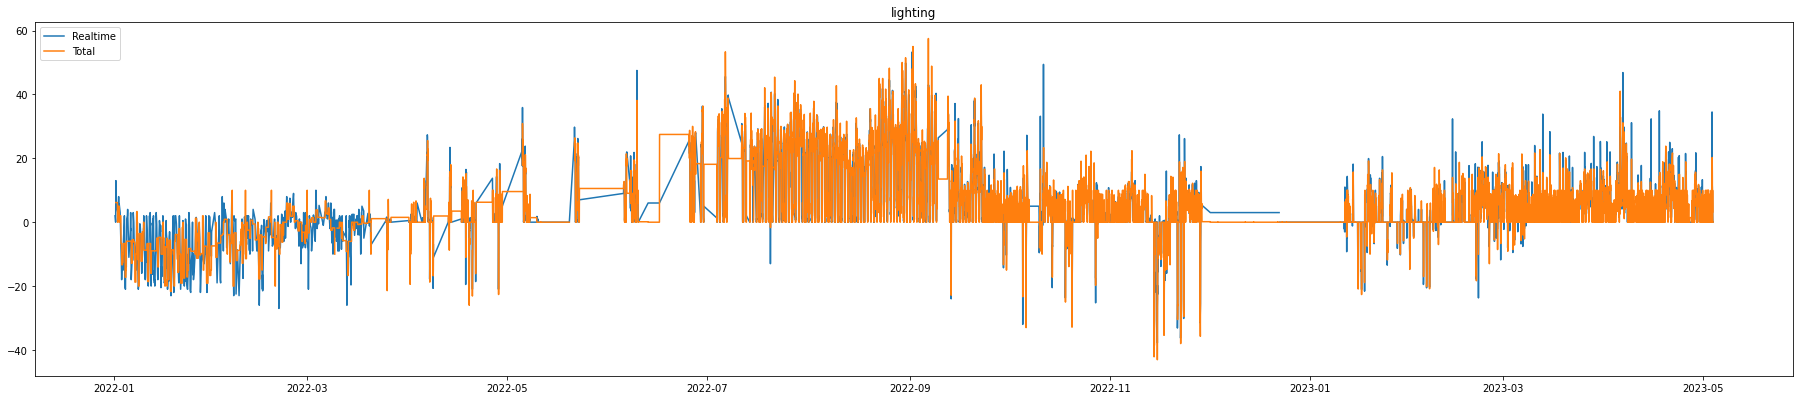

In [17]:
# flow based chilled water return and supply temp confidence

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(index, ton_chw, label = 'Realtime') #(return - supply) * flow
plt.plot(index, diff_chw, label = 'Total')
plt.legend(loc="upper left")
plt.title('lighting')


# 1) 

ValueError: x and y must have same first dimension, but have shapes (11712,) and (768,)

<Figure size 432x288 with 0 Axes>

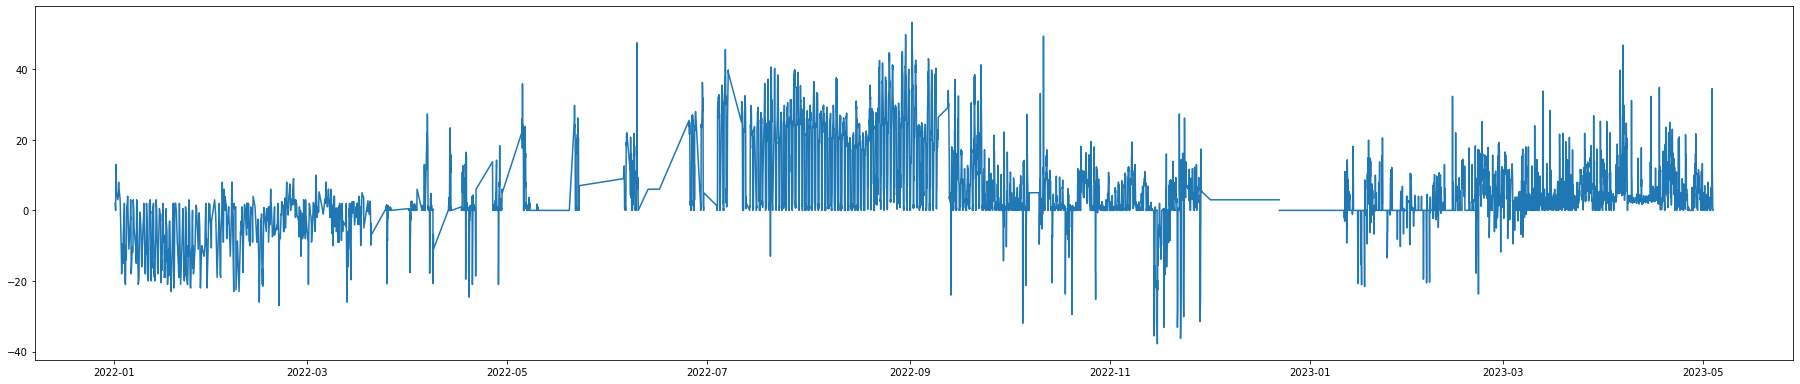

In [28]:
sd = "2022-01-01"
ed = "2023-06-01"

n_index = APIdata['Kendeda CHW'].loc[sd:ed].index

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(n_index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.plot(n_index, diff_chw.loc[sd:ed], label = 'Total')
plt.legend(loc="upper left")
plt.title('lighting')

# (return - supply) * flow

<Figure size 432x288 with 0 Axes>

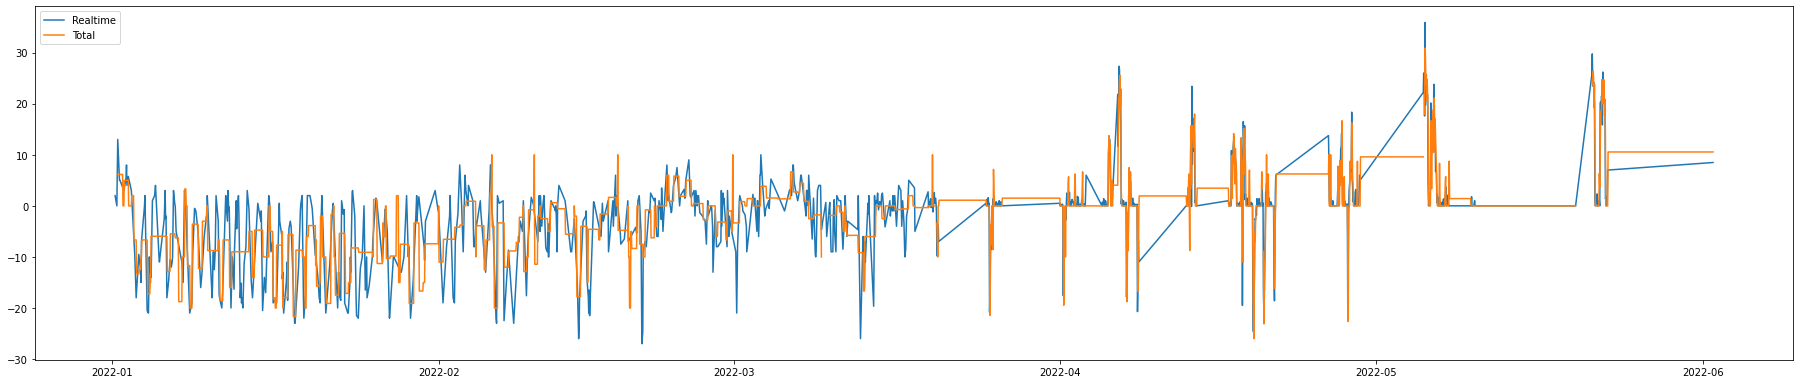

<Figure size 432x288 with 0 Axes>

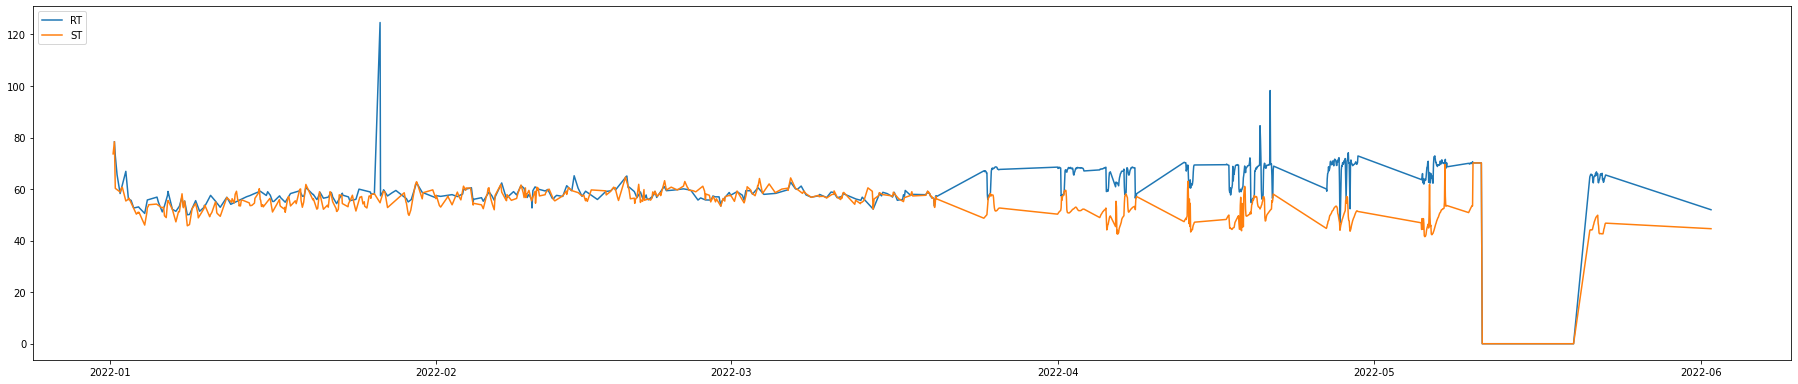

<Figure size 432x288 with 0 Axes>

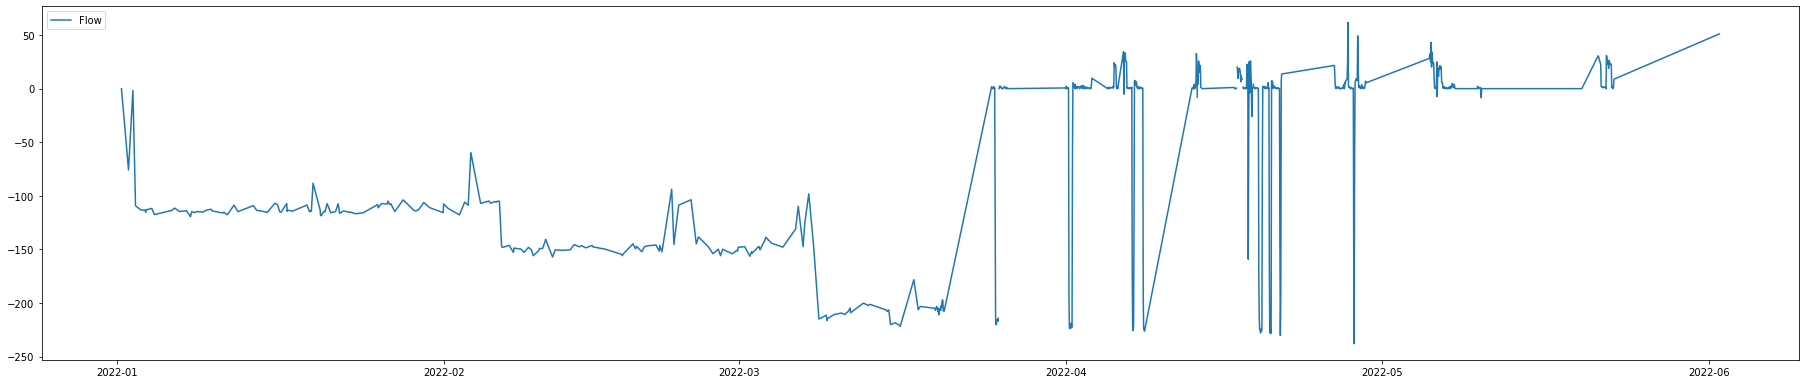

In [19]:
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(n_index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.plot(n_index, diff_chw.loc[sd:ed], label = 'Total')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(n_index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.plot(n_index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(n_index, f_chw.loc[sd:ed], label = 'Flow')
plt.legend(loc="upper left")

In [33]:
sd = "2022-01-01"
ed = "2023-01-01"

calc_flow = (APIdata['Kendeda CCHW RT'] - APIdata['Kendeda CCHW ST']) * APIdata['Kendeda CCHW F'] /200
n_index = calc_flow[sd:ed].index


In [35]:
calc_flow.loc[sd:ed]

2022-01-01 00:00:00    NaN
2022-01-01 01:00:00    NaN
2022-01-01 02:00:00    NaN
2022-01-01 03:00:00    NaN
2022-01-01 04:00:00    NaN
                      ... 
2023-01-01 19:00:00    0.0
2023-01-01 20:00:00    0.0
2023-01-01 21:00:00    0.0
2023-01-01 22:00:00    0.0
2023-01-01 23:00:00    0.0
Freq: H, Length: 8784, dtype: float64

<Figure size 432x288 with 0 Axes>

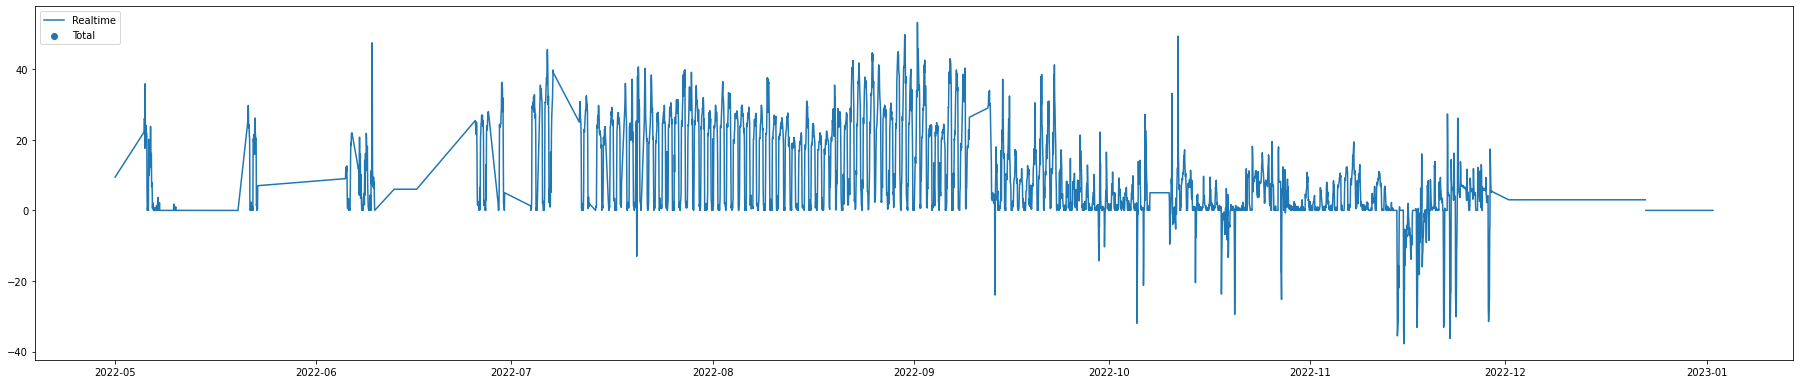

<Figure size 432x288 with 0 Axes>

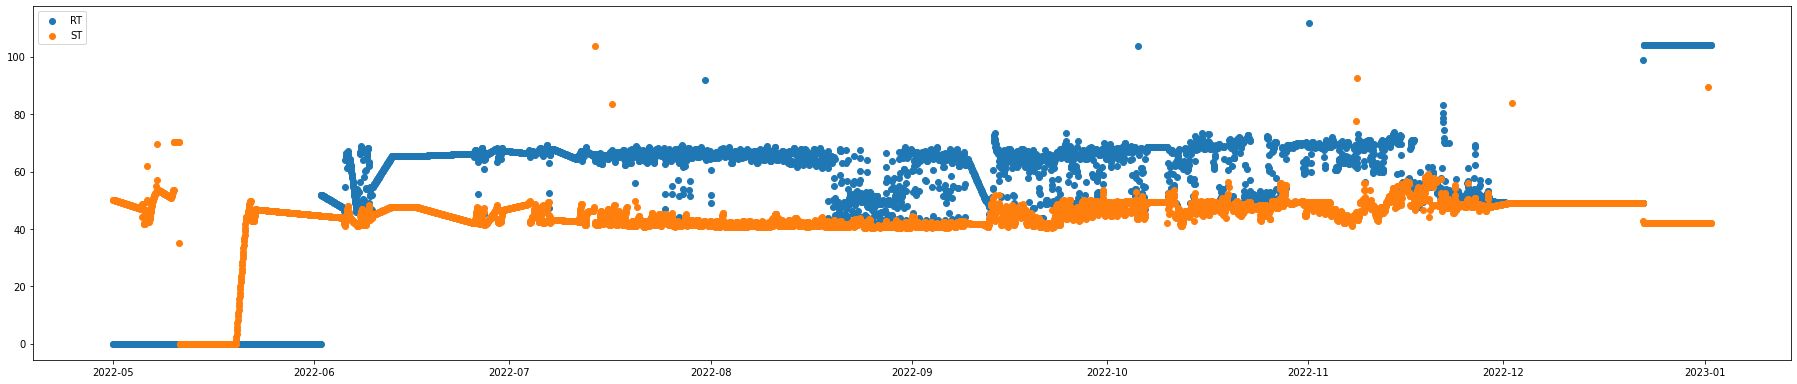

<Figure size 432x288 with 0 Axes>

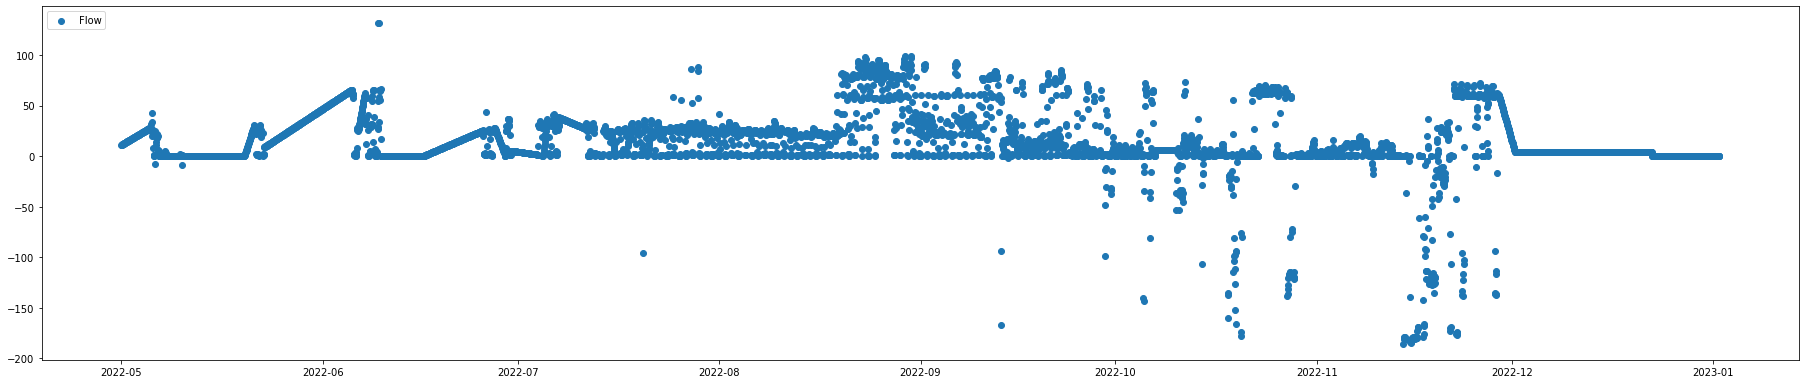

In [44]:
sd = "2022-05-01"
ed = "2023-01-01"

calc_flow = (APIdata['Kendeda CCHW RT'] - APIdata['Kendeda CCHW ST']) * APIdata['Kendeda CCHW F'] /22
n_index = calc_flow[sd:ed].index

calc_flow[abs(calc_flow) > 1000] = None

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.plot(n_index, calc_flow.loc[sd:ed], label = 'Calculated')
plt.plot(APIdata['Kendeda CCHW Ton'].loc[sd:ed].index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.scatter(diff_chw.loc[sd:ed].index, diff_chw.loc[sd:ed], label = 'Total')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.scatter(n_index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, f_chw.loc[sd:ed], label = 'Flow')
plt.legend(loc="upper left")

In [21]:
def highlight(series, val, colorSTR):
    # Create a mask to identify where the Series values equal 4
    mask = (series == val)

    # Find the start and end indices of each continuous section where the value equals 4
    section_start = mask & ~mask.shift(fill_value=False)
    section_end = mask & ~mask.shift(-1, fill_value=False)

    for start, end in zip(section_start[section_start].index, section_end[section_end].index):
        plt.axvspan(start, end, color=colorSTR, alpha=0.5)


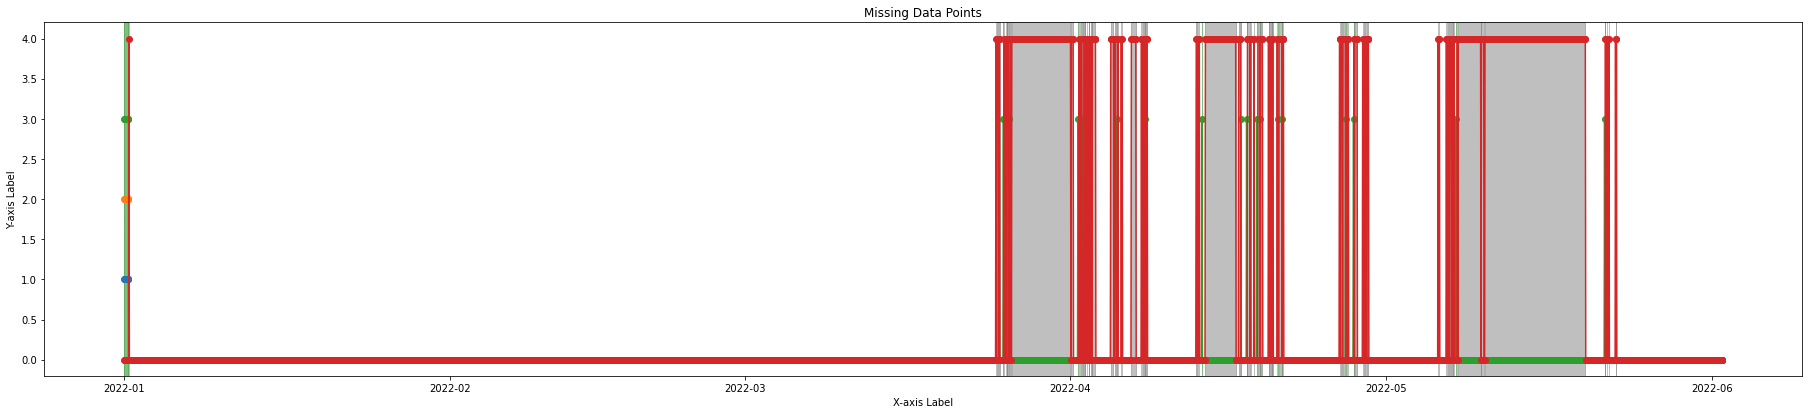

In [22]:
# Create binary arrays for missing data points
missing_RT = APIdata['Kendeda CCHW RT'].loc[sd:ed].isna()
missing_ST = APIdata['Kendeda CCHW ST'].loc[sd:ed].isna()
missing_F = f_chw.loc[sd:ed].isna()
no_flow = abs(APIdata['Kendeda CCHW F'].loc[sd:ed]) < 1

zero_array = APIdata['Kendeda CCHW RT'].loc[sd:ed]
zero_array[:] = 0

missing_RT_df = zero_array.copy()
missing_ST_df = zero_array.copy()
missing_F_df = zero_array.copy()
no_flow_df = zero_array.copy()

missing_RT_df[missing_RT] = 1
missing_ST_df[missing_RT] = 2
missing_F_df[missing_F] = 3
no_flow_df[no_flow] = 4

# Set the figure size
plt.figure(figsize=(31.5, 6.5))

# Plot missing data points as lines
plt.plot(n_index, missing_RT_df, label='Missing RT', linestyle='-', marker='o')
plt.plot(n_index, missing_ST_df, label='Missing ST', linestyle='-', marker='o')
plt.plot(n_index, missing_F_df, label='Missing F', linestyle='-', marker='o')
plt.plot(n_index, no_flow_df, label='No Flow', linestyle='-', marker='o')
highlight(missing_F_df, 3, 'green')
highlight(no_flow_df, 4, 'grey')

plt.title("Missing Data Points")
plt.xlabel("X-axis Label")
plt.ylabel("Y-axis Label")

plt.show()

<Figure size 432x288 with 0 Axes>

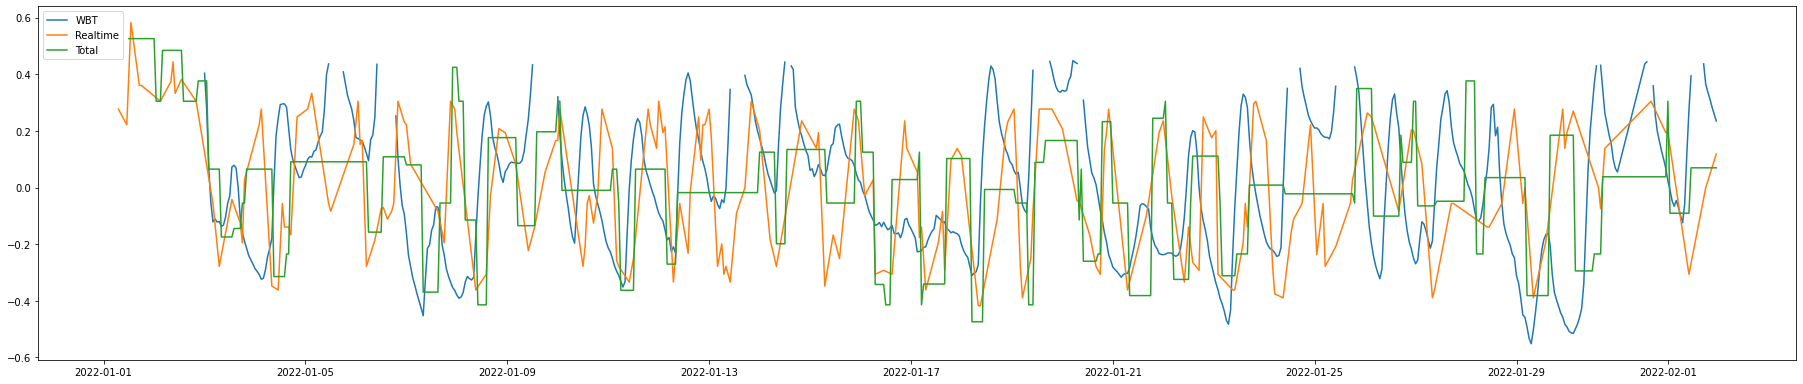

<Figure size 432x288 with 0 Axes>

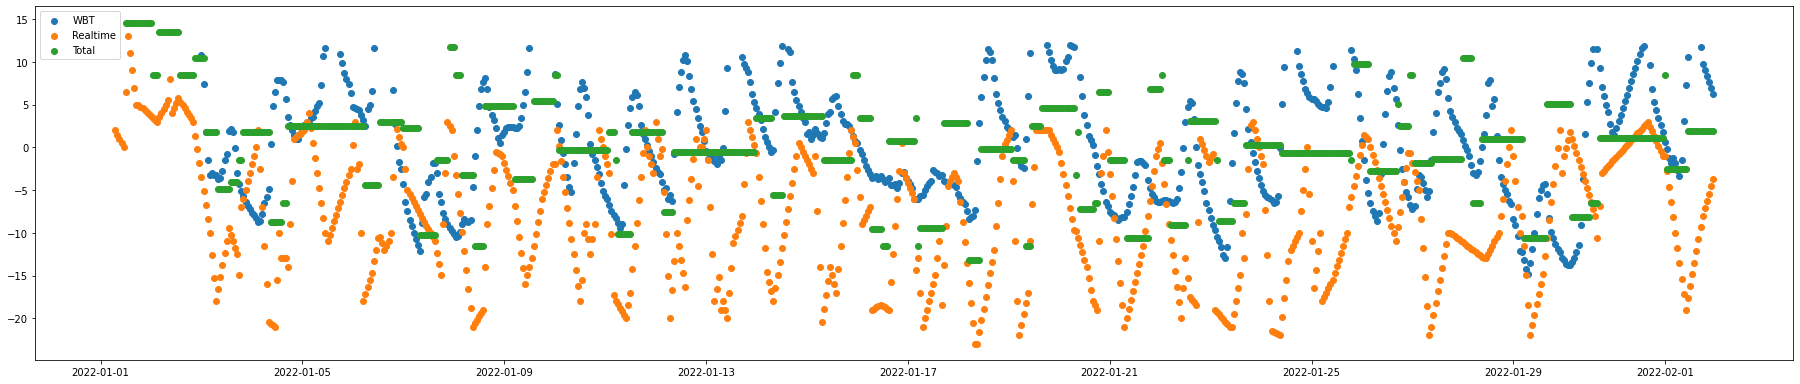

<Figure size 432x288 with 0 Axes>

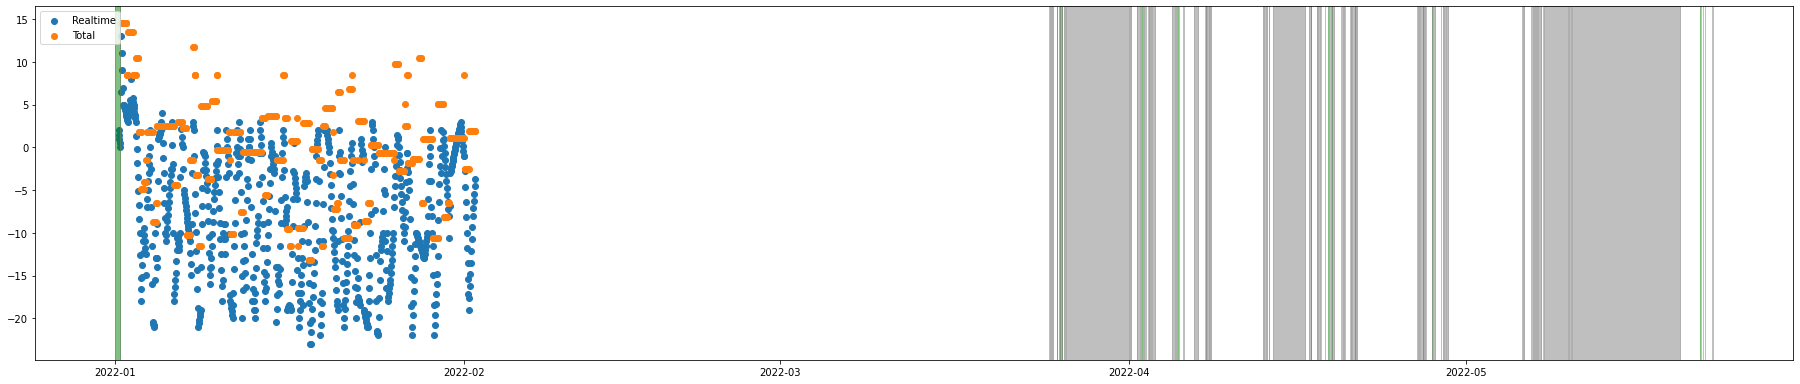

In [23]:
sd = "2022-01-01"
ed = "2022-02-01"

wbt = APIdata['WBT'][sd:ed].copy()

ton = APIdata['Kendeda CCHW Ton'][sd:ed].copy()
diff_chw = diff_chw[sd:ed].copy()

wbt[wbt > 50] = None
wbt = wbt - wbt.mean()
wbt_norm = wbt / (wbt.max() - wbt.min())

ton = ton - ton.mean()
ton_norm = ton/ (ton.max() - ton.min())

diff_chw = diff_chw - diff_chw.mean()
diff_chw_norm = diff_chw / (diff_chw.max() - diff_chw.min())

n_index = ton_norm.index
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.plot(n_index, wbt_norm, label = 'WBT')
plt.plot(n_index, ton_norm, label = 'Realtime')
plt.plot(n_index, diff_chw_norm, label = 'Total')
plt.legend(loc="upper left")



plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, wbt.loc[sd:ed], label = 'WBT')
plt.scatter(n_index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.scatter(n_index, diff_chw.loc[sd:ed], label = 'Total')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.scatter(n_index, diff_chw.loc[sd:ed], label = 'Total')
highlight(missing_F_df, 3, 'green')
highlight(no_flow_df, 4, 'grey')
plt.legend(loc="upper left")

In [24]:


plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, APIdata['Kendeda CCHW RT'].loc[sd:ed], label = 'RT')
plt.scatter(n_index, APIdata['Kendeda CCHW ST'].loc[sd:ed], label = 'ST')
highlight(missing_F_df, 3, 'green')
highlight(no_flow_df, 4, 'grey')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, APIdata['WBT'].loc[sd:ed], label = 'WBT')
plt.legend(loc="upper left")

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
plt.scatter(n_index, APIdata['Kendeda CCHW Ton'].loc[sd:ed], label = 'Realtime')
plt.scatter(n_index, diff_chw.loc[sd:ed], label = 'Total')
highlight(missing_F_df, 3, 'green')
highlight(no_flow_df, 4, 'grey')
plt.legend(loc="upper left")
plt.scatter(n_index, f_chw.loc[sd:ed], label = 'Flow')
highlight(missing_F_df, 3, 'green')
highlight(no_flow_df, 4, 'grey')
plt.legend(loc="upper left")

SyntaxError: invalid syntax (1402331074.py, line 10)

In [ ]:
calc_flow =(APIdata['Kendeda CCHW RT'] - APIdata['Kendeda CCHW ST']) * APIdata['Kendeda CCHW F']

plt.figure()
plt.figure().set_size_inches(31.5, 6.5)
#plt.scatter(n_index, wbt, label = 'WBT')

index = 
plt.scatter(n_index, APIdata['Kendeda CCHW Ton'], label = 'Realtime')
plt.scatter(n_index, diff_chw.loc, label = 'Total')
plt.legend(loc="upper left")
